**Eye-Tracking & Neurocognitive Intelligence | Eye-Tracking Foundations & Signal Analysis | Presented by: Reza Saadatyar (2026)**

**04 | Gaze Features and Fixation Scanpaths**

![Source-identified event features and fixation-centroid scanpath workflow](../../images/04_gaze_features_and_scanpaths.svg)

**Objective:** Convert event intervals produced in Notebook 03 into transparent per-record gaze features and an illustrative fixation-centroid path, while retaining the distinction between detector output and observed eye movement.

**Input evidence:** Notebook 02 prepared **2,778,008 samples across 40 recordings from 10 participants**. Notebook 03 recorded **7,015 I-VT fixations, 9,304 I-VT saccades and 5,409 I-DT fixations**. The present feature definitions use **I-VT events only**; I-DT remains a comparator, not a source of additional mixed event counts.

**Method scope:** Summarise validity, detected event counts and durations, peak saccade speed, approximate fixation-centroid path length and uncalibrated positive pupil area where available. This is a descriptive gaze-feature analysis, not reading-comprehension measurement, semantic word-level gaze mapping or clinical inference.

**Recorded execution:** Notebook 04 produced **40 per-record feature rows for 10 independent participants**, a feature dictionary and an empirical I-VT fixation-centroid path plot. Its saved missingness display reported **zero unavailable values in the recorded feature columns**. The SVG distinguishes this observed table coverage from a schematic centroid-path illustration. The scientific features remain detector-dependent and do not establish a cognitive outcome.


**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("eye_tracking_foundations")

# ----------------- 2. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 3. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure
from core.output_download import download_outputs_from_colab

# ------------------------ 4. Study Research Utilities ------------------------
from core.stage_outputs import ensure_stage_inputs
from gaze_source import read_stage
from gaze_features import record_features, feature_dictionary

# --------------------- 5. Output and Presentation Setup ----------------------
output_dir = root / "eye_tracking_foundations" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
plot_style(
    font_family="DejaVu Sans", title_size=12.5,
    title_weight="normal", label_size=11.5,
    label_weight="normal", tick_size=11,
    legend_size=10, figure_dpi=100, figure_size=(10, 4),
)
print("Current outputs:", output_dir)


Repository up to date.
Current outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_tracking_foundations/output


**02. Recover Prepared Samples and Detected Events**

Reuse the current `02_preprocessed_samples.csv` from Notebook 02 and `03_events.csv` from Notebook 03. The event table carries the original record and participant identities, method, event type, within-record timing and centroid coordinates.

For per-record feature calculation, the entire wide prepared sample table is unnecessary. Read only `record_id`, `participant_id`, `task`, `valid_for_motion` and `dP`, while retaining all event columns required for feature extraction. This reduces peak RAM relative to loading every gaze and velocity column again. Show the actual input scope and verify that the event record identifiers belong to the prepared sample set before computing features.




In [ ]:
# ============= 02. Recover Prepared Samples and Detected Events ==============

# ------------------------- 1. Verify Required Inputs -------------------------
ensure_stage_inputs(output_dir, 2, ("02_preprocessed_samples.csv",))
ensure_stage_inputs(output_dir, 3, ("03_events.csv",))

# ----------------- 2. Read Only the Necessary Source Fields ------------------
source_fields = [
    "record_id", "participant_id", "task", "valid_for_motion", "dP",
]
prepared = pd.read_csv(
    output_dir / "02_preprocessed_samples.csv",
    usecols=source_fields,
    dtype={"record_id": str, "participant_id": str, "task": str},
    low_memory=False,
)
events = read_stage(
    output_dir / "03_events.csv",
    ("record_id", "participant_id", "method", "event_type",
     "duration_ms", "mean_x_dva", "mean_y_dva", "peak_speed_dva_s",
     "start_sample"),
)

# --------------------- 3. Confirm Record and Task Scope ----------------------
source_ids = set(prepared["record_id"])
if not set(events["record_id"]).issubset(source_ids):
    raise ValueError("Notebook 03 events include records absent from Notebook 02.")
if events.empty:
    raise ValueError("No detected events are available for feature extraction.")
print("Source participants:", prepared["participant_id"].nunique())
print("Source recordings:", prepared["record_id"].nunique())
print("Prepared sample rows:", f"{len(prepared):,}")
print("Detected event rows:", f"{len(events):,}")
print("Event methods:", ", ".join(sorted(events["method"].unique())))
display(events[[
    "record_id", "method", "event_type", "duration_ms", "mean_x_dva", "mean_y_dva",
]].head(8))


Source participants: 10
Source recordings: 40
Prepared sample rows: 2,778,008
Detected event rows: 21,728
Event methods: IDT, IVT


,record_id,method,event_type,duration_ms,mean_x_dva,mean_y_dva
0,S_1001_S1_FXS,IVT,fixation,167.0,1.071407,-3.576353
1,S_1001_S1_FXS,IVT,saccade,25.0,0.430873,-2.677797
2,S_1001_S1_FXS,IVT,saccade,9.0,0.353679,-1.983445
3,S_1001_S1_FXS,IVT,fixation,103.0,0.314320,-2.209853
4,S_1001_S1_FXS,IVT,saccade,22.0,-0.139878,-0.861212
5,S_1001_S1_FXS,IVT,saccade,7.0,-0.275443,0.032375
6,S_1001_S1_FXS,IVT,fixation,143.0,-0.322445,-0.157511
7,S_1001_S1_FXS,IVT,fixation,702.0,-0.224086,-0.096284


**03. Calculate Record-Level Features**

For each source recording, extract only **I-VT** fixation and saccade events. Report valid gaze fraction, counts of both event classes, mean and median fixation duration, and mean event-peak saccade speed. The latter is derived from provisional detector events and may be influenced by the extreme speed estimates identified in Notebook 02.

Approximate scanpath length is the sum of Euclidean distances between successive **detected fixation centroids** in degrees of visual angle. It does not include a verified word-by-word reading trajectory, nor does it necessarily account for unobserved gaze between separated valid runs. Only finite, positive pupil-area observations from motion-eligible samples enter the optional **uncalibrated** pupil summary. Missing estimates stay missing instead of being set to zero.

Save `04_features_by_record.csv` together with a compact feature dictionary documenting each feature and unit.


In [4]:
# ==================== 03. Calculate Record-Level Features ====================

features = pd.DataFrame([
    record_features(part, events[events.record_id.eq(rid)])
    for rid, part in prepared.groupby("record_id",sort=True)
])
features.to_csv(output_dir / "04_features_by_record.csv", index=False)
feature_dictionary().to_csv(output_dir / "04_feature_dictionary.csv",index=False)
display(features)


,record_id,participant_id,task,valid_fraction,n_fixations_ivt,n_saccades_ivt,mean_fixation_ms,median_fixation_ms,mean_saccade_peak_dva_s,scanpath_length_dva,pupil_median_uncalibrated
0,S_1001_S1_FXS,001,FXS,0.967566,36,13,387.166667,265.5,247.562896,8.706277,1987.0
1,S_1001_S1_HSS,001,HSS,0.996387,295,370,223.610169,128.0,275.853651,3066.191899,2284.0
2,S_1001_S1_RAN,001,RAN,0.986779,311,374,258.691318,174.0,334.510035,1417.964468,1937.0
3,S_1001_S1_TEX,001,TEX,0.966713,253,321,166.470356,152.0,357.058468,991.255860,1460.0
4,S_1002_S1_FXS,002,FXS,0.968356,58,15,141.000000,130.0,394.341395,8.415860,3407.0
5,S_1002_S1_HSS,002,HSS,0.990959,247,299,179.404858,137.0,371.497826,2182.033796,3696.0
6,S_1002_S1_RAN,002,RAN,0.990869,310,262,141.383871,115.0,271.732189,1239.903402,3352.0
7,S_1002_S1_TEX,002,TEX,0.985557,202,288,126.415842,115.0,366.481097,736.164067,1708.0
8,S_1003_S1_FXS,003,FXS,0.986599,8,9,1813.000000,621.5,297.212592,9.901850,7776.0
9,S_1003_S1_HSS,003,HSS,0.997424,209,287,392.861244,329.0,324.895301,2963.463870,7317.0


**04. Visualise an Illustrative Fixation-Centroid Path**

Display up to the first 100 **I-VT fixation events** from a selected source recording, ordered by their original `start_sample`. Join their detected centroid coordinates in sequence and mark the first selected fixation.

The plot is a **detector-derived centroid sequence**, not an observed gaze trajectory between every fixation, a stimulus-specific area-of-interest map or a measure of reading comprehension. If the selected recording contains no qualifying fixation events, display a clear explanatory label instead of inventing a trajectory.


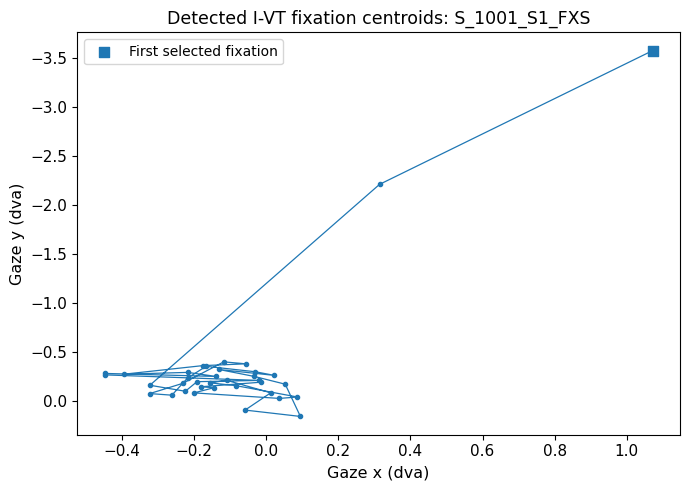

In [5]:
# =========== 04. Visualise an Illustrative Fixation-Centroid Path ============

rid = str(prepared.record_id.iloc[0])
fix = events[(events.record_id==rid) & (events.method=="IVT") &
             (events.event_type=="fixation")].sort_values("start_sample").head(100)
fig, ax = plt.subplots(figsize=(7,5))
if len(fix):
    ax.plot(fix.mean_x_dva, fix.mean_y_dva, lw=0.9, marker="o", markersize=3)
    ax.scatter(fix.mean_x_dva.iloc[0], fix.mean_y_dva.iloc[0],marker="s",s=50,
               label="First selected fixation")
else:
    ax.text(0.5,0.5,"No qualifying fixations in selected record",
            ha="center",transform=ax.transAxes)
ax.set(xlabel="Gaze x (dva)",ylabel="Gaze y (dva)", title=f"Detected I-VT fixation centroids: {rid}")
ax.invert_yaxis()
ax.legend(loc="best") if len(fix) else None
fig.tight_layout()
save_figure(fig,output_dir / "04_scanpath.png")
plt.show()


**05. Review Feature Coverage**

The feature table contains **40 feature records from 10 participants**, with four source tasks per participant. The saved missingness report shows **zero unavailable values across its reported feature columns**. This is observed availability in the selected subset, not evidence that pupil measurements are always available in GazeBase or that all calculated features are physiologically reliable.

The independent unit for Notebook 05's exploratory uncertainty analysis is the **participant**, not an eye sample, fixation interval or task recording. Notebook 05 first checks that every feature row matches Notebook 01's source quality table by record ID, participant, task and valid gaze fraction, and then constructs participant-by-task summaries.


In [6]:
# ======================== 05. Review Feature Coverage ========================

print("Feature records:",len(features),"Unique participants:",features.participant_id.nunique())
print("Unavailable values by feature:")
display(features.isna().sum().rename("missing"))


Feature records: 40 Unique participants: 10
Unavailable values by feature:


,missing
record_id,0
participant_id,0
task,0
valid_fraction,0
n_fixations_ivt,0
n_saccades_ivt,0
mean_fixation_ms,0
median_fixation_ms,0
mean_saccade_peak_dva_s,0
scanpath_length_dva,0


**06. Save Feature Tables**

Notebook 04 produces three outputs: `04_features_by_record.csv` (40 per-record rows), `04_feature_dictionary.csv` (feature definitions and units) and `04_scanpath.png` (an empirical, detector-derived I-VT fixation-centroid sequence).

Notebook 05 reads the feature table and `01_quality_by_record.csv` without recalculating the eye-event detectors.


In [ ]:
# ===================== 06. Export Named Current Features =====================
download_outputs_from_colab("eye_tracking_foundations/output", "04")


------------------------------------------------------------------------
Notebook 04
Files packaged: 3
  + 04_feature_dictionary.csv
  + 04_features_by_record.csv
  + 04_scanpath.png
Download ZIP from Colab Contents: /content/eye_tracking_foundations_Notebook_04_Outputs.zip
